# Heart Disease Prediction — Feature Engineering and Model Development

## Objective

Develop and compare at least two classification models to predict the presence or absence of heart disease using the UCI Cleveland dataset.

## Modelling strategy

* Use a stratified training/test split.
* Impute missing values inside the preprocessing pipeline.
* Standardize numerical features for Logistic Regression.
* One-hot encode categorical features.
* Compare Logistic Regression and Random Forest using five-fold cross-validation.
* Evaluate the selected model on the held-out test set using accuracy, precision, recall, F1-score and ROC-AUC.

## Target definition

* `0`: no heart disease
* `1`: heart disease present

In [1]:
#Importing and loading dataset


from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_validate,
)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report,
    ConfusionMatrixDisplay,
)

# Locate the project root
PROJECT_ROOT = Path.cwd()

if not (PROJECT_ROOT / "data" / "raw" / "processed.cleveland.data").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_FILE = PROJECT_ROOT / "data" / "raw" / "processed.cleveland.data"

COLUMNS = [
    "age", "sex", "cp", "trestbps", "chol",
    "fbs", "restecg", "thalach", "exang",
    "oldpeak", "slope", "ca", "thal", "num",
]

df = pd.read_csv(
    RAW_FILE,
    header=None,
    names=COLUMNS,
    na_values=["?"],
    skipinitialspace=True,
)

for col in COLUMNS:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Convert original target: 0 = absent, 1–4 = present
df = df.dropna(subset=["num"]).copy()
df["target"] = (df["num"] > 0).astype(int)

# Exclude both the original target and the derived target from inputs
X = df.drop(columns=["num", "target"])
y = df["target"]

print("Project root:", PROJECT_ROOT)
print("Dataset shape:", df.shape)
print("\nTarget distribution:")
print(y.value_counts().sort_index())
print("\nInput features:", X.columns.tolist())
print("\nMissing values:")
print(X.isna().sum()[X.isna().sum() > 0])

Project root: c:\Users\Himaanish\Documents\heart-disease-mlops
Dataset shape: (303, 15)

Target distribution:
target
0    164
1    139
Name: count, dtype: int64

Input features: ['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach', 'exang', 'oldpeak', 'slope', 'ca', 'thal']

Missing values:
ca      4
thal    2
dtype: int64


In [2]:
#Separating numerical and categorical features


numeric_features = [
    "age",
    "trestbps",
    "chol",
    "thalach",
    "oldpeak",
]

categorical_features = [
    "sex",
    "cp",
    "fbs",
    "restecg",
    "exang",
    "slope",
    "ca",
    "thal",
]

print("Numerical features:", numeric_features)
print("Categorical features:", categorical_features)

assert set(numeric_features + categorical_features) == set(X.columns)

Numerical features: ['age', 'trestbps', 'chol', 'thalach', 'oldpeak']
Categorical features: ['sex', 'cp', 'fbs', 'restecg', 'exang', 'slope', 'ca', 'thal']


In [3]:
#Building the preprocessing pipeline

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore")),
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features),
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [4]:
#Creating the training and test sets


X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

print("Training records:", len(X_train))
print("Test records:", len(X_test))

print("\nTraining target proportions:")
print(y_train.value_counts(normalize=True).sort_index().round(3))

print("\nTest target proportions:")
print(y_test.value_counts(normalize=True).sort_index().round(3))

Training records: 242
Test records: 61

Training target proportions:
target
0    0.541
1    0.459
Name: proportion, dtype: float64

Test target proportions:
target
0    0.541
1    0.459
Name: proportion, dtype: float64


In [5]:
#Defining the two classification models

models = {
    "Logistic Regression": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", LogisticRegression(max_iter=2000, random_state=42)),
    ]),
    "Random Forest": Pipeline(steps=[
        ("preprocessor", preprocessor),
        ("classifier", RandomForestClassifier(
            n_estimators=300,
            random_state=42,
            class_weight=None,
        )),
    ]),
}

print("Models defined:", list(models.keys()))

Models defined: ['Logistic Regression', 'Random Forest']


In [7]:
#Comparing models using five-fold cross-validation

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42,
)

scoring = {
    "accuracy": "accuracy",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1",
    "roc_auc": "roc_auc",
}

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring=scoring,
        return_train_score=False,
        n_jobs=-1,
    )

    result = {"model": name}

    for metric in scoring:
        values = scores[f"test_{metric}"]
        result[f"{metric}_mean"] = values.mean()
        result[f"{metric}_std"] = values.std()

    cv_results.append(result)

cv_results_df = pd.DataFrame(cv_results)

display(
    cv_results_df.sort_values(
        "roc_auc_mean",
        ascending=False,
    ).round(3)
)

,model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
0,Logistic Regression,0.847,0.010,0.877,0.054,0.783,0.046,0.825,0.007,0.902,0.014
1,Random Forest,0.814,0.023,0.797,0.027,0.801,0.080,0.796,0.036,0.894,0.033


In [8]:
#Fitting both models and evaluating the held-out test set

test_results = []
fitted_models = {}

for name, model in models.items():
    model.fit(X_train, y_train)
    fitted_models[name] = model

    predictions = model.predict(X_test)
    probabilities = model.predict_proba(X_test)[:, 1]

    test_results.append({
        "model": name,
        "accuracy": accuracy_score(y_test, predictions),
        "precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "f1": f1_score(
            y_test, predictions, zero_division=0
        ),
        "roc_auc": roc_auc_score(y_test, probabilities),
    })

test_results_df = pd.DataFrame(test_results)

display(
    test_results_df.sort_values(
        "roc_auc",
        ascending=False,
    ).round(3)
)

,model,accuracy,precision,recall,f1,roc_auc
0,Logistic Regression,0.885,0.839,0.929,0.881,0.966
1,Random Forest,0.869,0.812,0.929,0.867,0.944


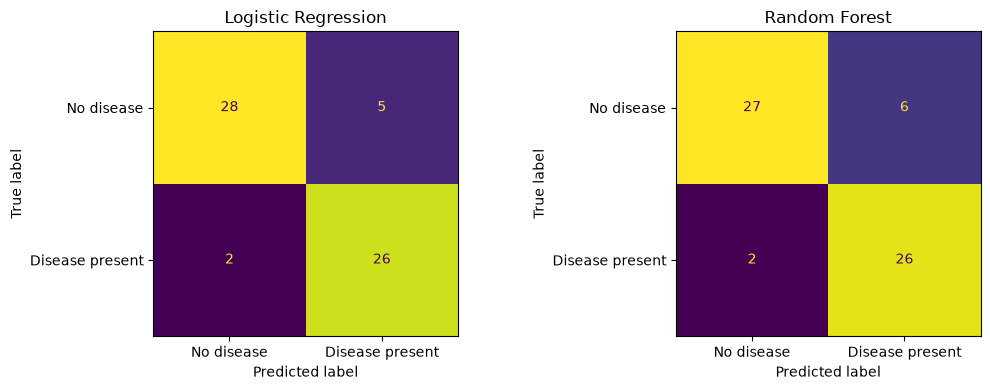


Logistic Regression
                 precision    recall  f1-score   support

     No disease       0.93      0.85      0.89        33
Disease present       0.84      0.93      0.88        28

       accuracy                           0.89        61
      macro avg       0.89      0.89      0.89        61
   weighted avg       0.89      0.89      0.89        61


Random Forest
                 precision    recall  f1-score   support

     No disease       0.93      0.82      0.87        33
Disease present       0.81      0.93      0.87        28

       accuracy                           0.87        61
      macro avg       0.87      0.87      0.87        61
   weighted avg       0.88      0.87      0.87        61



In [9]:
#Viewing confusion matrices and classification reports

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

for ax, (name, model) in zip(axes, fitted_models.items()):
    ConfusionMatrixDisplay.from_estimator(
        model,
        X_test,
        y_test,
        display_labels=["No disease", "Disease present"],
        ax=ax,
        colorbar=False,
    )
    ax.set_title(name)

plt.tight_layout()
plt.show()

for name, model in fitted_models.items():
    print(f"\n{name}")
    print(classification_report(
        y_test,
        model.predict(X_test),
        target_names=["No disease", "Disease present"],
        zero_division=0,
    ))